<a href="https://colab.research.google.com/github/rania04286-r/cv-license-plate-detection/blob/main/03_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline: Canny + morphology + contours

**What this does, in plain words**
1. Loads the manifest made by `02_duplicate_check.ipynb`.
2. Learns what a real plate looks like (shape and size) from the **train** images.
3. Runs the baseline detector: grayscale, smooth, edges, join letters into blocks, find outlines, keep plate-like shapes.
4. Tunes a few settings on **train** images, then reports precision / recall / F1 on **val** images.
5. Shows where it fails (missed plates or wrong boxes). That tells us which improvement to try.

**Note** the test images are locked (the code refuses to load them).

## 1. Settings

In [1]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

TEAM = Path("/content/drive/MyDrive/CV_Team_Project")
LOCAL_DATA = Path("/content/data")
DRIVE_DATA = TEAM / "dataset" / "extracted"
DATA_DIR = LOCAL_DATA if (LOCAL_DATA / "train").exists() else DRIVE_DATA
MANIFEST = TEAM / "outputs" / "manifest.csv"            # made by 02_duplicate_check
CODE_DIR = TEAM / "code"                                # where plate_eval.py is saved
OUT_DIR = TEAM / "outputs"
SEED = 42

sys.path.insert(0, str(CODE_DIR))
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import plate_eval as pe
print("images are read from:", DATA_DIR)

Mounted at /content/drive
images are read from: /content/drive/MyDrive/CV_Team_Project/dataset/extracted


## 2. The manifest (which image belongs to which split)

In [2]:
manifest = pd.read_csv(MANIFEST)
manifest.groupby("split").agg(images=("image", "count"), plates=("n_boxes", "sum"))

,images,plates
split,,
test,1496,1591
train,7165,7498
val,1464,1548


## 3. Look at real examples (green = the real plate)

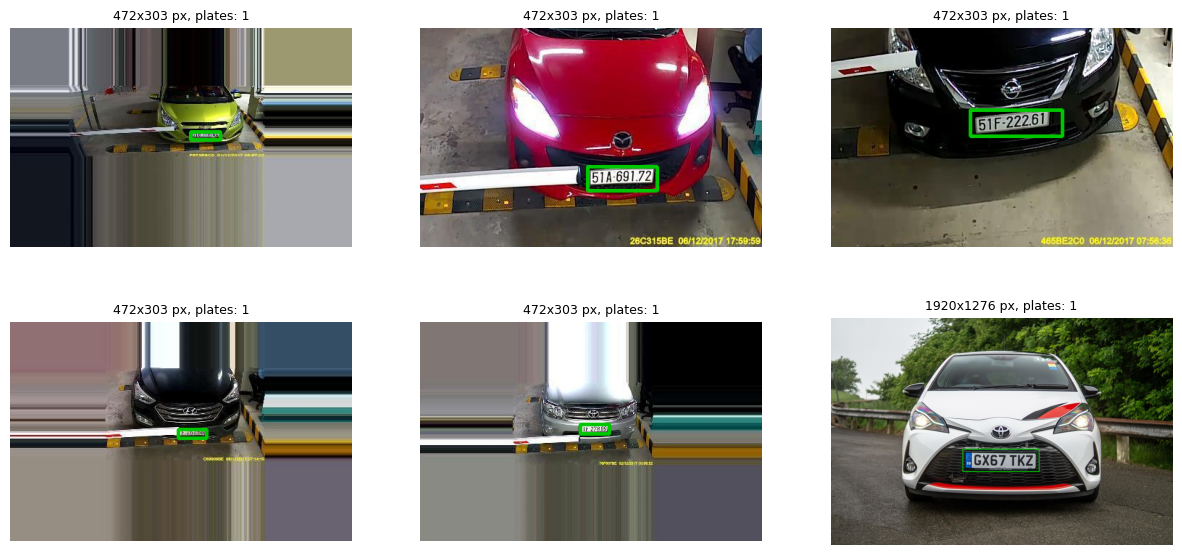

In [3]:
rows = pe.get_rows(manifest, "train", n=6, seed=SEED)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
    img, gts = pe.load_example(DATA_DIR, r)
    ax.imshow(pe.draw(img, gts)); ax.axis("off")
    ax.set_title(f"{img.shape[1]}x{img.shape[0]} px, plates: {len(gts)}", fontsize=9)
plt.show()

## 4. What does a real plate look like? (measured on all train images, nothing else)
We use these numbers to set the shape rules, so the choice is explainable. **If you see two clumps** in the first histogram (long one-line plates and squarer two-line plates, for example on motorbikes), widen the aspect range.

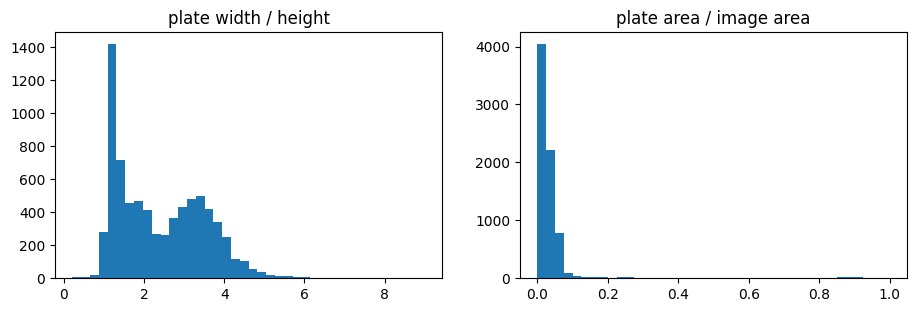

plates measured: 7498
aspect range kept (2nd to 98th percentile): 1.04 to 4.67
area range kept:   0.0007 to 0.4073 of the image


In [4]:
import json
aspects, areas = [], []
for _, r in manifest[manifest["split"] == "train"].iterrows():      # every train image; boxes come from the manifest
    for x1, y1, x2, y2 in json.loads(r["boxes"]):
        if x2 > x1 and y2 > y1:
            aspects.append((x2 - x1) / (y2 - y1))
            areas.append((x2 - x1) * (y2 - y1) / (r["width"] * r["height"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(aspects, bins=40); ax[0].set_title("plate width / height")
ax[1].hist(areas, bins=40);   ax[1].set_title("plate area / image area")
plt.show()

ASPECT = (float(np.percentile(aspects, 2)), float(np.percentile(aspects, 98)))
AREA = (float(np.percentile(areas, 2)), float(np.percentile(areas, 98)))
print(f"plates measured: {len(aspects)}")
print(f"aspect range kept (2nd to 98th percentile): {ASPECT[0]:.2f} to {ASPECT[1]:.2f}")
print(f"area range kept:   {AREA[0]:.4f} to {AREA[1]:.4f} of the image")

## 5. The baseline detector
Each numbered line is one pipeline step (these are the boxes of the pipeline diagram).

In [5]:
def make_detector(canny_lo=80, canny_hi=200, kernel=(17, 5), fill_min=0.35, width=640, aspect=ASPECT, area=AREA):
    ker = cv2.getStructuringElement(cv2.MORPH_RECT, kernel)

    def detect(img, debug=False):
        H, W = img.shape[:2]
        s = width / W                                                  # work at a fixed width so settings mean the same for every image
        small = cv2.resize(img, (width, max(1, int(H * s))))
        gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)                 # 1. grayscale (colour is not needed)
        smooth = cv2.bilateralFilter(gray, 9, 75, 75)                  # 2. smooth noise, keep edges sharp
        edges = cv2.Canny(smooth, canny_lo, canny_hi)                  # 3. find edges (plates have many sharp character edges)
        closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, ker)         # 4. join nearby edges so the letters become one block
        cnts = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]   # 5. outlines of the blocks
        sh, sw = gray.shape
        found = []
        for c in cnts:                                                 # 6. keep only plate-like outlines
            x, y, w, h = cv2.boundingRect(c)
            if w < 5 or h < 5:
                continue
            a = w / h                                                  # shape: width / height
            ar = w * h / (sw * sh)                                     # size: share of the image
            fill = cv2.contourArea(c) / (w * h)                        # how rectangular the blob is
            if aspect[0] <= a <= aspect[1] and area[0] <= ar <= area[1] and fill >= fill_min:
                found.append([x / s, y / s, (x + w) / s, (y + h) / s, fill])
        found = pe.nms(found)                                          # 7. drop overlapping duplicates
        if debug:
            return found, dict(gray=gray, smooth=smooth, edges=edges, closed=closed, small=small)
        return found
    return detect

## 6. See the pipeline on one val image

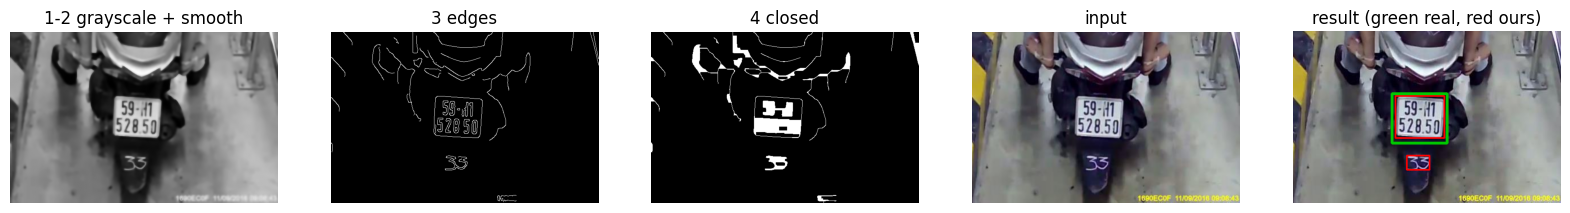

In [6]:
r = pe.get_rows(manifest, "val", n=1, seed=SEED).iloc[0]
img, gts = pe.load_example(DATA_DIR, r)
found, steps = make_detector()(img, debug=True)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (title, im) in zip(axes[:4], [("1-2 grayscale + smooth", steps["smooth"]), ("3 edges", steps["edges"]), ("4 closed", steps["closed"]), ("input", steps["small"][:, :, ::-1])]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
axes[4].imshow(pe.draw(img, gts, found)); axes[4].set_title("result (green real, red ours)"); axes[4].axis("off")
plt.show()

## 7. First score, on 1,000 **train** images
Precision = of our boxes, how many were real plates. Recall = of the real plates, how many we found. A box counts as correct if it overlaps a real plate by at least half (IoU 0.5).

In [7]:
cache = {}      # keeps the images in memory so repeated runs are fast
first = pe.evaluate(make_detector(), manifest, "train", DATA_DIR, n=1000, seed=SEED, cache=cache)
print(pe.summary(first))

train: 1000 images | precision 0.220 | recall 0.312 | F1 0.258 | TP 325 FP 1151 FN 716 | 21 ms/image


## 8. Try a few settings (still on the same 1,000 train images; this step takes several minutes)
Settings are chosen on **train**. Val is only for reporting, so the number is honest.

In [8]:
import itertools
grid = list(itertools.product([(50, 150), (80, 200), (100, 250)],          # Canny thresholds
                              [(9, 3), (17, 5), (25, 7), (15, 15)],        # closing kernel (width, height)
                              [0.25, 0.4]))                                # minimum rectangularity
results = []
for (lo, hi), k, f in grid:
    r = pe.evaluate(make_detector(lo, hi, k, f), manifest, "train", DATA_DIR, n=1000, seed=SEED, cache=cache)
    results.append(dict(canny=(lo, hi), kernel=k, fill_min=f, precision=r["precision"], recall=r["recall"], f1=r["f1"]))
grid_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
grid_df.head(8)

,canny,kernel,fill_min,precision,recall,f1
0,"(100, 250)","(17, 5)",0.40,0.2614,0.3295,0.2915
1,"(100, 250)","(9, 3)",0.40,0.2341,0.3612,0.2841
2,"(80, 200)","(9, 3)",0.40,0.2298,0.3660,0.2823
3,"(80, 200)","(17, 5)",0.40,0.2419,0.3026,0.2689
4,"(100, 250)","(9, 3)",0.25,0.1838,0.4073,0.2533
5,"(50, 150)","(9, 3)",0.40,0.2061,0.3247,0.2521
6,"(80, 200)","(9, 3)",0.25,0.1785,0.4073,0.2482
7,"(100, 250)","(25, 7)",0.40,0.2349,0.2622,0.2478


## 9. Report on ALL validation images with the best settings

In [9]:
best = grid_df.iloc[0]
settings = dict(canny=tuple(int(v) for v in best["canny"]), kernel=tuple(int(v) for v in best["kernel"]),
                fill_min=float(best["fill_min"]), aspect=ASPECT, area=AREA, width=640, tuned_on="1000 train images")
detector = make_detector(settings["canny"][0], settings["canny"][1], settings["kernel"], settings["fill_min"])
val = pe.evaluate(detector, manifest, "val", DATA_DIR, n=None, seed=SEED)       # n=None = every validation image
print(pe.summary(val))
print()
print(pd.Series(pe.error_types(val)).to_string())
pe.save_results(val, OUT_DIR / "baseline_val.json", settings=settings, method="baseline: Canny + closing + contours")
print("\nsaved", OUT_DIR / "baseline_val.json")

val: 1464 images | precision 0.260 | recall 0.329 | F1 0.290 | TP 509 FP 1450 FN 1039 | 20 ms/image

images with a missed plate     967
images with a wrong box        823
images with both               535
perfect images                 209
total wrong boxes (FP)        1450
total missed plates (FN)      1039

saved /content/drive/MyDrive/CV_Team_Project/outputs/baseline_val.json


## 10. Where does it fail?
Look at both galleries and write down what you see. **Which is bigger: missed plates or wrong boxes?** That decides the main improvement:
- mostly **wrong boxes** -> add a check on each candidate (HOG + classifier)
- mostly **missed plates** -> better edges / contrast (Sobel + Canny, CLAHE) or more candidates

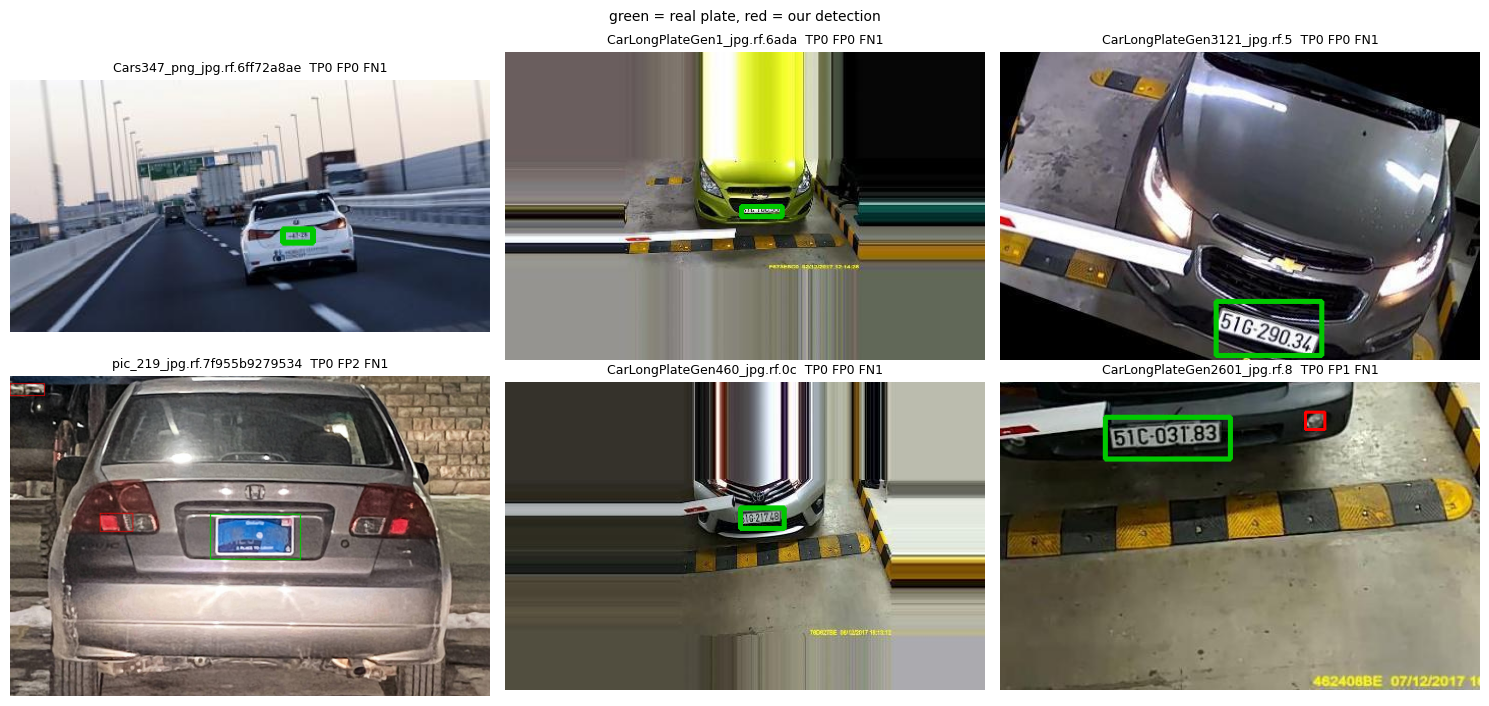

In [10]:
pe.gallery(val, "miss", k=6)

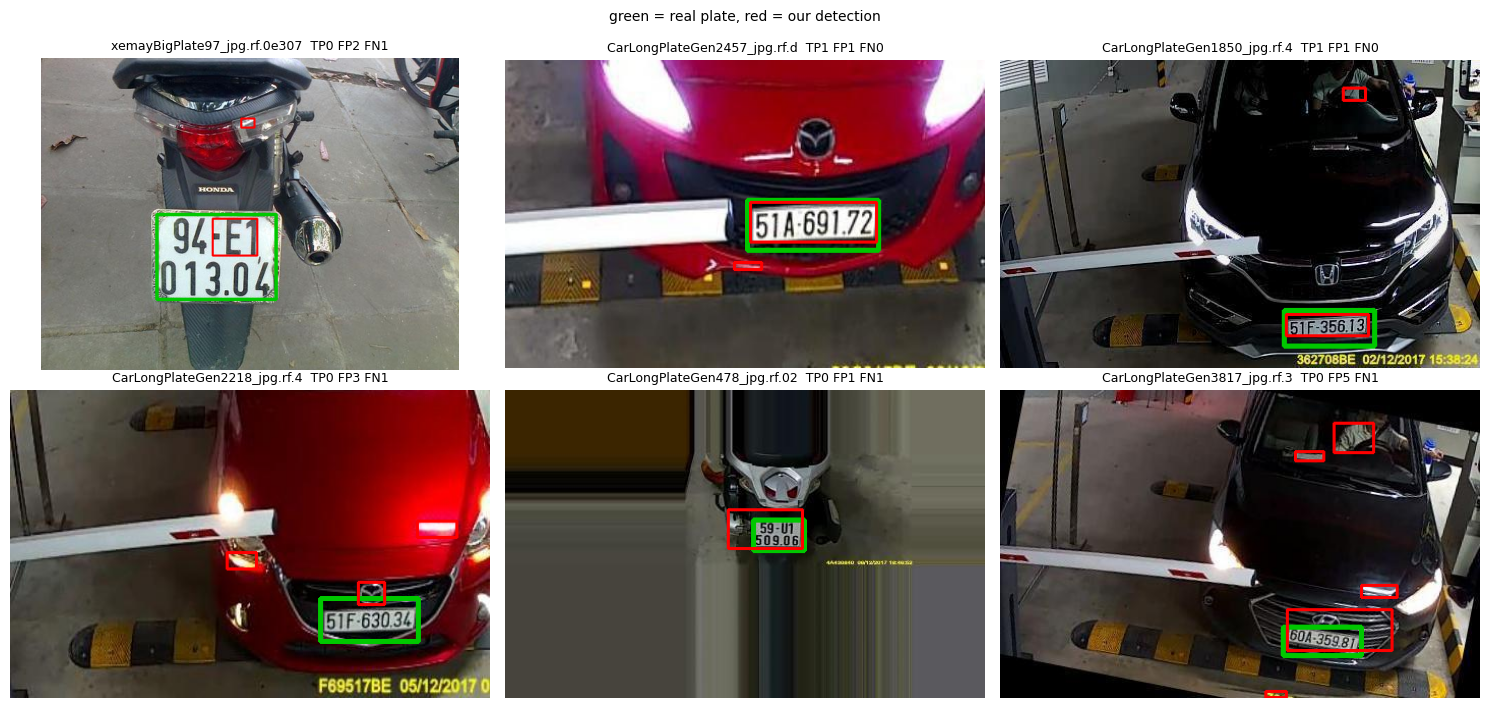

In [11]:
pe.gallery(val, "wrong", k=6)

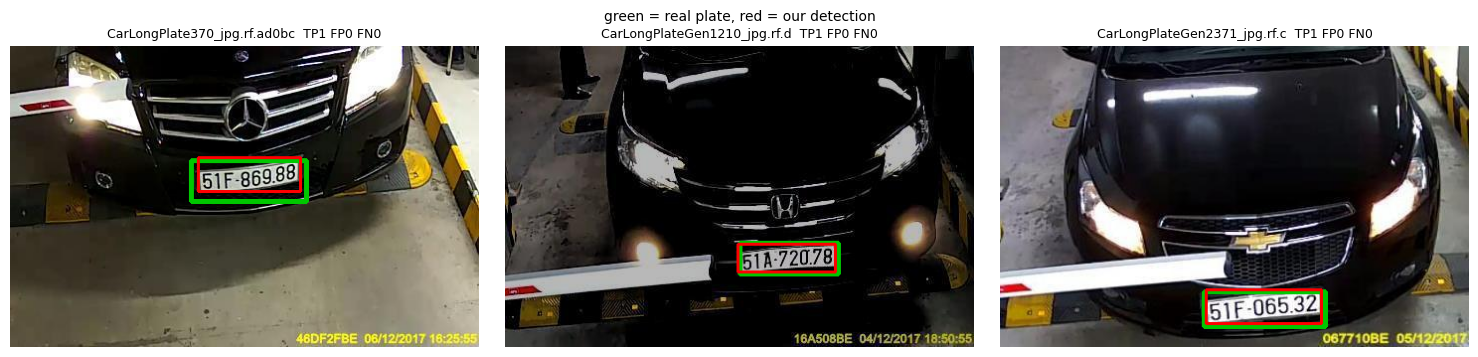

In [12]:
pe.gallery(val, "good", k=3)

## 11. How many real plates does the candidate stage find at all?
A verifier (HOG + SVM) can only keep or reject boxes that already exist, so this number is the ceiling for the improvement. We use very permissive shape rules (keep almost every outline) and count the share of real plates covered by any candidate. **Send this table to whoever builds the HOG + SVM.**

In [13]:
loose_aspect, loose_area = (0.8, 8.0), (0.0003, 0.6)          # very permissive shape rules
rows = []
for k in [(9, 3), (17, 5), (25, 7), (15, 15)]:
    det = make_detector(settings["canny"][0], settings["canny"][1], k, 0.0, aspect=loose_aspect, area=loose_area)
    r = pe.evaluate(det, manifest, "train", DATA_DIR, n=1000, seed=SEED, cache=cache)
    rows.append(dict(kernel=k, candidates_per_image=round((r["tp"] + r["fp"]) / r["n_images"], 1), candidate_recall=r["recall"]))
pd.DataFrame(rows)

,kernel,candidates_per_image,candidate_recall
0,"(9, 3)",9.9,0.5235
1,"(17, 5)",7.2,0.4083
2,"(25, 7)",5.9,0.3141
3,"(15, 15)",5.4,0.2719
